In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_column", None)
pd.set_option("display.width", 120)

df = pd.read_csv("netflix_titles.csv")


In [18]:
print("dataset shape:" , df.shape)
display(df.head())
display(df.tail())

dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [19]:
display(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration',
       'listed_in', 'description'],
      dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [21]:
display(df.describe())

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [22]:
display(df.nunique())

,0
show_id,8807
type,2
title,8807
director,4528
cast,7692
country,748
date_added,1767
release_year,74
rating,17
duration,220


In [23]:
print( "number of duplicate rows:" , df.duplicated().sum())
display(df.isnull().sum())
display(df.isnull().mean() * 100)

number of duplicate rows: 0


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


,0
show_id,0.000000
type,0.000000
title,0.000000
director,29.908028
cast,9.367549
country,9.435676
date_added,0.113546
release_year,0.000000
rating,0.045418
duration,0.034064


In [24]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    values = df[col].dropna()
    suspicious = values[values != values.str.strip()].unique()

    if len(suspicious) > 0:
        print(col, suspicious)

title ['Consequences\xa0']
date_added [' August 4, 2017' ' December 23, 2018' ' December 15, 2018'
 ' July 1, 2017' ' July 26, 2019' ' May 26, 2016' ' November 1, 2019'
 ' December 2, 2017' ' March 15, 2019' ' October 1, 2019'
 ' December 15, 2017' ' April 4, 2017' ' December 28, 2016'
 ' March 31, 2018' ' February 1, 2019' ' January 1, 2018'
 ' February 24, 2018' ' December 14, 2018' ' July 20, 2018'
 ' January 17, 2018' ' September 7, 2016' ' October 31, 2018'
 ' August 21, 2017' ' October 8, 2013' ' November 1, 2017'
 ' December 1, 2018' ' March 16, 2016' ' December 15, 2015'
 ' September 8, 2015' ' May 28, 2016' ' December 3, 2019'
 ' November 1, 2016' ' November 3, 2015' ' December 1, 2019'
 ' May 1, 2018' ' April 17, 2016' ' March 22, 2015' ' September 16, 2018'
 ' April 16, 2019' ' June 1, 2017' ' September 1, 2019' ' March 1, 2017'
 ' July 12, 2019' ' December 31, 2015' ' May 31, 2015' ' January 13, 2016'
 ' December 18, 2014' ' September 22, 2016' ' May 18, 2017'
 ' January 1,

all the date added have unnecessary spaces at the beginning

In [25]:
for col in categorical_columns:
    values = df[col].dropna().astype(str)
    lower_values = values.str.lower()

    for value in lower_values[lower_values.duplicated()].unique():
        matches = values[lower_values == value].unique()

        if len(matches) > 1:
            print(col, matches)

title ['FullMetal Alchemist' 'Fullmetal Alchemist']
title ['Death Note' 'DEATH NOTE']
title ['Esperando la carroza' 'Esperando La Carroza']
title ['Love in a Puff' 'Love In A Puff']
title ['Sin senos sí hay paraíso' 'Sin Senos sí Hay Paraíso']
director ['Kevin Macdonald' 'Kevin MacDonald']
director ['Fernando Frías de la Parra' 'Fernando Frías De La Parra']


inconsistent capitalization

In [26]:
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: show_id
show_id
s1       1
s2       1
s3       1
s4       1
s5       1
        ..
s8803    1
s8804    1
s8805    1
s8806    1
s8807    1
Name: count, Length: 8807, dtype: int64

Column: type
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Column: title
title
Dick Johnson Is Dead     1
Blood & Water            1
Ganglands                1
Jailbirds New Orleans    1
Kota Factory             1
                        ..
Zodiac                   1
Zombie Dumb              1
Zombieland               1
Zoom                     1
Zubaan                   1
Name: count, Length: 8807, dtype: int64

Column: director
director
NaN                                       2634
Rajiv Chilaka                               19
Raúl Campos, Jan Suter                      18
Suhas Kadav                                 16
Marcus Raboy                                16
                                          ... 
Milla Harrison-Hansley, Alicky Sussman       1
Drew Stone             

misplaced values of 66 min, 74 min and 84 min in the 'rating' column

In [27]:
df_clean = df.copy()
df_clean["director"] = df_clean["director"].fillna('Unknown')
df_clean["cast"] = df_clean["cast"].fillna('Unknown')
df_clean["country"] = df_clean["country"].fillna('unknown')
df_clean = df_clean.dropna(subset=["date_added" , "rating" , "duration"])


for the director, cast and country, they have been filled with 'Unknown' since removing a large amount of records would affect the data and be more likely to introduce bias. Also the mode wasnt used since we cant guess directors, cast or a country

the date added, rating, and duration had a only a few lines of missing values and removing them is less likely to affect the data set in a negative way and not much information would be lost

In [28]:
df_clean["date_added"] = df_clean["date_added"].str.strip()
df_clean["title"] = df_clean["title"].str.lower().str.title()
df_clean["director"] = df_clean["director"].str.lower().str.title()
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"])

categorical_columns = df_clean.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df_clean[col].value_counts())


Column: show_id
show_id
s1       1
s2       1
s3       1
s4       1
s5       1
        ..
s8803    1
s8804    1
s8805    1
s8806    1
s8807    1
Name: count, Length: 8790, dtype: int64

Column: type
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Column: title
title
Fullmetal Alchemist         2
Love In A Puff              2
Esperando La Carroza        2
Sin Senos Sí Hay Paraíso    2
Death Note                  2
                           ..
Better Call Saul            1
Fronteras                   1
Polaroid                    1
The Coldest Game            1
We Bare Bears               1
Name: count, Length: 8785, dtype: int64

Column: director
director
Unknown                                                          2621
Rajiv Chilaka                                                      19
Raúl Campos, Jan Suter                                             18
Suhas Kadav                                                        16
Marcus Raboy                           

for both title and director. they were changed to lowercase then captialized the first letter of each word so it's in a title format and consistent

the date added was changed to datetime format

In [29]:
df_clean['release_year'].describe()


,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


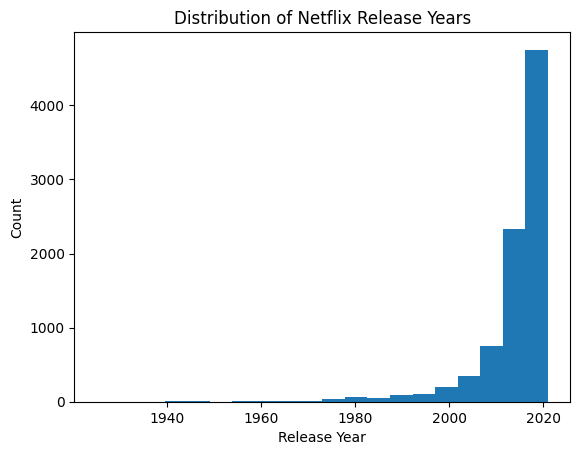

In [30]:
plt.hist(df_clean['release_year'], bins=20)
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.title('Distribution of Netflix Release Years')
plt.show()

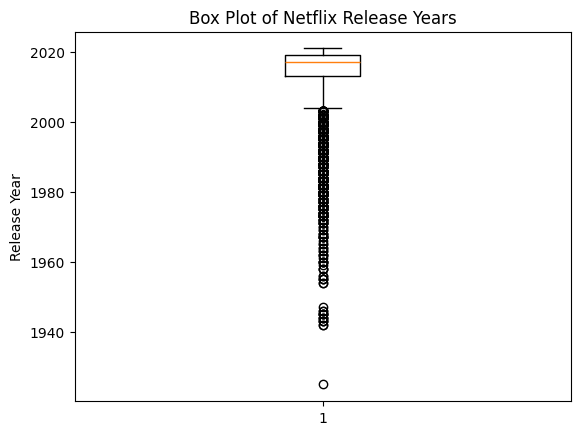

In [31]:
plt.boxplot(df_clean['release_year'])
plt.ylabel('Release Year')
plt.title('Box Plot of Netflix Release Years')
plt.show()

In [32]:
Q1 = df_clean['release_year'].quantile(0.25)
Q3 = df_clean['release_year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

Q1: 2013.0
Q3: 2019.0
IQR: 6.0
Lower boundary: 2004.0
Upper boundary: 2028.0


In [33]:
outliers = df_clean[
    (df_clean['release_year'] < lower_bound) |
    (df_clean['release_year'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))
display(outliers['release_year'].value_counts().sort_index())

Number of potential outliers: 717


,count
release_year,
1925,1
1942,2
1943,3
1944,3
1945,4
1946,2
1947,1
1954,2
1955,3


every outlier will be retained since movies can be released at an older date than the lower boundary and it would be inaccurate and biased to remove them

In [34]:
print( "number of duplicate rows:" , df_clean.duplicated().sum())
display(df_clean.isnull().sum())

number of duplicate rows: 0


,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [35]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8790 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   object        
 1   type          8790 non-null   object        
 2   title         8790 non-null   object        
 3   director      8790 non-null   object        
 4   cast          8790 non-null   object        
 5   country       8790 non-null   object        
 6   date_added    8790 non-null   datetime64[ns]
 7   release_year  8790 non-null   int64         
 8   rating        8790 non-null   object        
 9   duration      8790 non-null   object        
 10  listed_in     8790 non-null   object        
 11  description   8790 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 892.7+ KB


In [36]:
print(df_clean["type"].value_counts())
print(df_clean["rating"].value_counts())
print(df_clean["country"].value_counts().head(20))

type
Movie      6126
TV Show    2664
Name: count, dtype: int64
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64
country
United States                    2809
India                             972
unknown                           829
United Kingdom                    418
Japan                             243
South Korea                       199
Canada                            181
Spain                             145
France                            124
Mexico                            110
Egypt                             106
Turkey                            105
Nigeria                            95
Australia                          85
Taiwan                             81
Indonesia                          79
Brazil                             77
Philippines 

In [37]:
print(df_clean["release_year"].min())
print(df_clean["release_year"].max())

1925
2021


In [38]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (8807, 12)
Cleaned dataset shape: (8790, 12)


## **Summary**
the issues discovered were the missing datas in director, cast, country, date added, rating and duration. for the categorical records, since they had many null values, removing them would affect the record so they were filled with 'Unknown' to retain the record and not invent our own inaccrate data. for the numerical records they were removed. they were a total of 0.193% of the entire data set so removing it would not affect the data set as much. there were some inconsistencies in the data, such as the date added having spaces at the start, some titles and directors being the same but with different capitalization, and suspicious duration values in the rating column. the date added was converted to date-time format, the titles and directors were all converted to lowercase then capitalzed the first letter of each word, and the records of wrong durations in ratings were removed. data cleaning's objective was to teach me how to indentify data quality issues and apply the most suitable solution to deal with them since it does not have a fixed solution and mainly depends on the problem itself

In [39]:
df_clean.to_csv('netflix_titles_cleaned.csv', index=False)